# Fashion MNIST Image Classification using KNN

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import time

# Load datasets
train_df = pd.read_csv('/content/drive/MyDrive/PCCSL508/EXP7/fashion-mnist_train.csv')
test_df = pd.read_csv('/content/drive/MyDrive/PCCSL508/EXP7/fashion-mnist_test.csv')

print(f"Training data shape: {train_df.shape}")
print(f"Testing data shape: {test_df.shape}")
display(train_df.head())

Training data shape: (60000, 785)
Testing data shape: (10000, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
# Preprocessing
# Separate features (pixels) and labels
X_train = train_df.iloc[:, 1:].values / 255.0
y_train = train_df.iloc[:, 0].values

X_test = test_df.iloc[:, 1:].values / 255.0
y_test = test_df.iloc[:, 0].values

# Define class names for Fashion MNIST
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

### Experimenting with different values of K
We will evaluate $K = [1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 100]$ to analyze the trade-off between accuracy and computational cost. Note: KNN can be slow on large datasets like this.

In [ ]:
k_values = [1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 100]
results = []

for k in k_values:
    start_time = time.time()
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    end_time = time.time()

    acc = accuracy_score(y_test, y_pred)
    duration = end_time - start_time
    results.append({'K': k, 'Accuracy': acc, 'Time (s)': duration})
    print(f"K={k} | Accuracy: {acc:.4f} | Time: {duration:.2f}s")

results_df = pd.DataFrame(results)
display(results_df)

K=1 | Accuracy: 0.8567 | Time: 41.28s
K=3 | Accuracy: 0.8584 | Time: 36.44s
K=5 | Accuracy: 0.8589 | Time: 35.94s
K=7 | Accuracy: 0.8558 | Time: 36.17s
K=9 | Accuracy: 0.8561 | Time: 35.81s
K=11 | Accuracy: 0.8556 | Time: 37.73s
K=13 | Accuracy: 0.8543 | Time: 42.11s
K=15 | Accuracy: 0.8514 | Time: 37.96s
K=17 | Accuracy: 0.8505 | Time: 35.78s
K=19 | Accuracy: 0.8488 | Time: 38.04s
K=21 | Accuracy: 0.8462 | Time: 35.99s
K=100 | Accuracy: 0.8198 | Time: 38.26s


,K,Accuracy,Time (s)
0,1,0.8567,41.284203
1,3,0.8584,36.437742
2,5,0.8589,35.936902
3,7,0.8558,36.167361
4,9,0.8561,35.812597
5,11,0.8556,37.729565
6,13,0.8543,42.112188
7,15,0.8514,37.960819
8,17,0.8505,35.779838
9,19,0.8488,38.037757


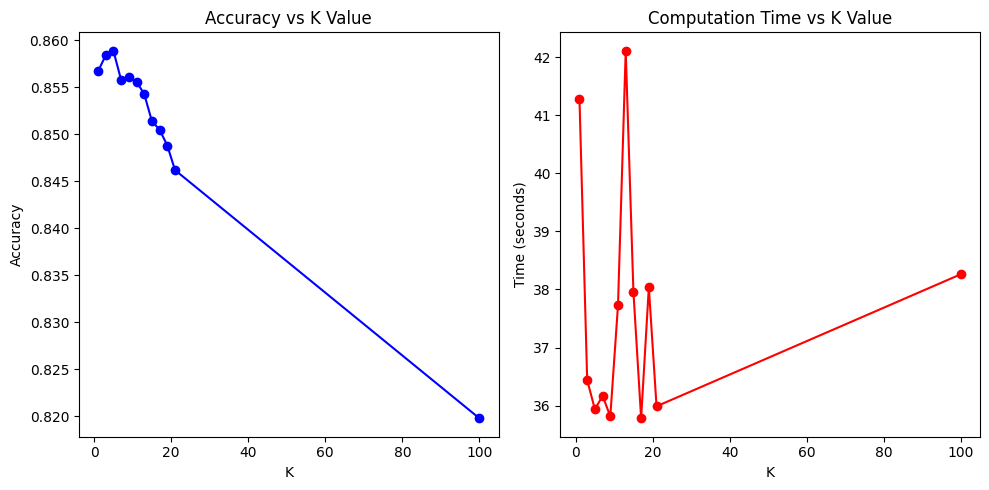

In [ ]:
# Visualization of the impact of K
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.plot(results_df['K'], results_df['Accuracy'], marker='o', color='b')
plt.title('Accuracy vs K Value')
plt.xlabel('K')
plt.ylabel('Accuracy')

plt.subplot(1, 2, 2)
plt.plot(results_df['K'], results_df['Time (s)'], marker='o', color='r')
plt.title('Computation Time vs K Value')
plt.xlabel('K')
plt.ylabel('Time (seconds)')

plt.tight_layout()
plt.show()